This notebook is to check the first visit and visualization

In [1]:
import duckdb
import matplotlib.pyplot as plt
from ga4case.path import USERS, FIGURES

In [2]:
con = duckdb.connect()
con.sql(
    f"create or replace view users as select * from read_parquet('{USERS.as_posix()}')"
);

In [3]:
# Check new users visit between Nov 1st and Dec 24th and did not buy product in the first visit
con.sql("""
    create or replace view target as
    select
        *,
        case
            when began_checkout = 1 then '5: began checkout'
            when viewed_product = 1 then '4: viewed a product'
            when distinct_pages >= 2 then '3: two or more pages'
            when active_seconds >=10 then '2: one page, 10 s or more'
            else '1: one page, under 10 s'
        end as first_visit_depth,
        coalesce(next_visit_page_view_start <= first_visit_end + interval 7 day, false) as came_back,
        coalesce(next_visit_start <= first_visit_end + interval 7 day, false) as came_back_any_visit,
        coalesce(later_purchase_start <= first_visit_end + interval 7 day, false) as purchase_later
    from users
    where first_session_number = 1
        and purchased_in_first_visit = 0
        and first_visit_start < timestamp '2020-12-25'     
""");

In [4]:
# Check the size of the target cohort
con.sql("""
    select
        count(*) as users,
        min(first_visit_start)::date as first_arrival,
        max(first_visit_start):: date as last_arrival,
        round(100.0 * avg(came_back::int), 1) as pct_came_back,
        round(100.0* avg(came_back_any_visit::int), 1) as pct_came_back_any_visit,
        round(100* avg(purchase_later::int), 2) as pct_purchase_later,
        sum(purchase_later::int) as later_purchaser
    from target
""").df()

,users,first_arrival,last_arrival,pct_came_back,pct_came_back_any_visit,pct_purchase_later,later_purchaser
0,152860,2020-11-01,2020-12-24,10.3,15.9,0.57,878.0


In [5]:
# Check activities of the first visit within 7 days
act_table = con.sql("""
    select
        first_visit_depth,
        count(*) as users,
        round(100.0 * count(*) / sum(count(*)) over (),1) as pct_users,
        round(100.0 * avg(came_back::int), 1) as pct_came_back,
        round(100* avg(purchase_later::int), 2) as pct_purchase_later,
        sum(purchase_later::int) as later_purchaser,
        round(100.0*sum(purchase_later::int) / sum(sum(purchase_later::int)) over (), 1) as pct_of_later_purchaser
    from target
    group by first_visit_depth
    order by first_visit_depth
""").df()
act_table

,first_visit_depth,users,pct_users,pct_came_back,pct_purchase_later,later_purchaser,pct_of_later_purchaser
0,"1: one page, under 10 s",67359,44.1,6.8,0.06,38.0,4.3
1,"2: one page, 10 s or more",24366,15.9,7.4,0.13,31.0,3.5
2,3: two or more pages,29027,19.0,14.1,0.56,164.0,18.7
3,4: viewed a product,28561,18.7,17.2,1.87,533.0,60.7
4,5: began checkout,3547,2.3,11.5,3.16,112.0,12.8


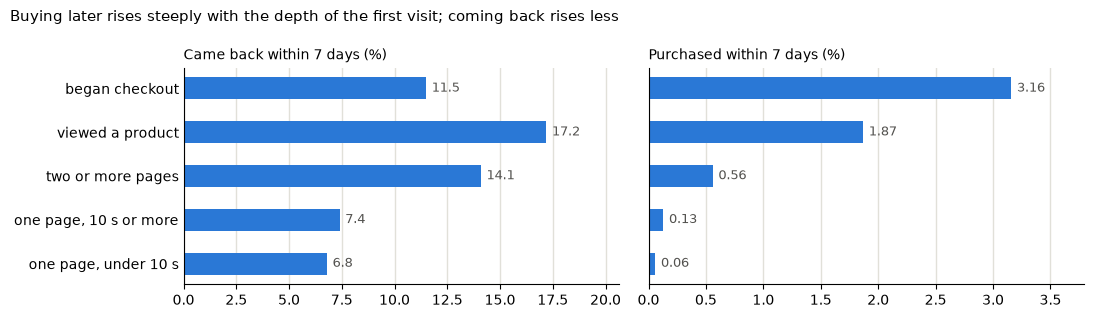

In [6]:
labels = act_table["first_visit_depth"].str.slice(3)
panels = [
    ("pct_came_back", "Came back within 7 days (%)", "{:.1f}"),
    ("pct_purchase_later", "Purchased within 7 days (%)", "{:.2f}"),
]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey = True)
for ax, (column, title, fmt) in zip(axes, panels):
    bars = ax.barh(labels, act_table[column], color="#2a78d6", height=0.5)
    ax.bar_label(bars, labels=[fmt.format(v) for v in act_table[column]],
                 padding=4, color="#52514e", fontsize=9)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlim(0, act_table[column].max() * 1.2)
    ax.grid(axis="x", color="#e1e0d9", linewidth=1)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
fig.suptitle("Buying later rises steeply with the depth of the first visit; coming back rises less",
             x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIGURES / "first_visit_depth_outcomes.png", dpi=500, bbox_inches="tight")

Findings:
- 60% of new users viewed one page, with around 7% (6.8% and 7.4% in two groups) came back but only 0.08% bought product within 7 days: (38 + 31) / (67359 + 24,366) = 0.08 %
- 'viewed a product' accounts for 18.7% but 60.7% of later purchasers.
- Came back within 7 days and Purchase within 7 days do not rank the same way:
    - viewed a product rank the highest return rate: 17.2%. 
    - began checkout rank the highest purchase rate: 3.16%.
- Predictive but not causal: table does not show that getting a visitor to view a product will increase the purchase.